# California housing, step by step

Each row of this dataset is a district of California in the 1990 census, described by eight numbers, together with the **median value of its houses**. The task is to **predict that value** for a district from the other eight: **a regression**. Every step of a supervised workflow appears here once, written by hand: looking at the data, splitting it, scaling it, training a model, predicting, measuring the error and looking at the errors. [California housing with pipelines](california_with_pipelines.ipynb) does the same with a fraction of the code; here each step is visible.

The data come with scikit-learn, cleaned and ready to use: rooms, bedrooms and occupants are averages per household, the value is in hundreds of thousands of dollars, and there are no missing values and no text. *California housing with pipelines* and the [California housing worked example](https://github.com/avidaldo/california_e2e) use the same 20,640 districts in the version of Aurélien Géron's book, which keeps the counts of each district and adds, on purpose, a text column and some missing values, so that preparing them can be taught.

## The data

scikit-learn downloads the dataset the first time it is used. Each row is a *block group*, the smallest area for which the census publishes data, with typically 600 to 3,000 people:

| Column | Meaning |
| --- | --- |
| `MedInc` | Median income of the households, in tens of thousands of dollars |
| `HouseAge` | Median age of the houses, in years |
| `AveRooms`, `AveBedrms` | Average number of rooms and of bedrooms per household |
| `Population` | Number of people |
| `AveOccup` | Average number of people per household |
| `Latitude`, `Longitude` | Position of the district |
| `MedHouseVal` | **Target:** median value of the houses, in hundreds of thousands of dollars |

In [ ]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True).frame
housing.shape

(20640, 9)

In [ ]:
housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
housing.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


Two things stand out. The features live on very different scales: income goes from 0.5 to 15, population from 3 to almost 36,000. And some maxima are far from everything else: a district with 141 rooms per household, another with 1,243 people per household, averages that no home has. They are kept here; what they are (holiday homes whose owners live elsewhere, an institution such as a prison) and what to do with such values is part of data preparation ([Outliers and capped values](../../data-preparation/deep-dives/outliers.ipynb)).

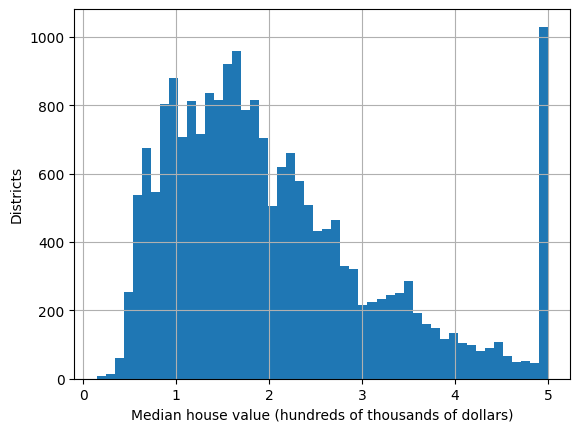

In [ ]:
import matplotlib.pyplot as plt

housing["MedHouseVal"].hist(bins=50)
plt.xlabel("Median house value (hundreds of thousands of dollars)")
plt.ylabel("Districts")
plt.show()

The tall bar at the right end is not a real cluster of expensive districts. The census recorded every value above \$500,000 as \$500,001, so about 5% of the districts sit exactly at 5.0, whatever their houses were really worth. A model trained on these values can't learn anything above that limit, and its errors near the limit will look odd.

The correlation of each feature with the target measures how closely they rise and fall together along a straight line, from -1 to 1:

In [ ]:
housing.corr()["MedHouseVal"].drop("MedHouseVal").sort_values(ascending=False).round(3)

MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64

Income is by far the feature most related to the value. The others look weak, but a correlation only sees one feature at a time and only straight-line relations: latitude and longitude are weak *separately*, yet together they say whether a district is on the coast, which matters a great deal. The model will use all eight together.

## Splitting

The model is judged on districts it never saw: 20% of them are held back as the test set. [Overfitting and the train/test split](../ml-fundamentals/overfitting_and_the_split.ipynb) explains why, and how to choose the split.

In [ ]:
from sklearn.model_selection import train_test_split

X = housing.drop(columns="MedHouseVal")
y = housing["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((16512, 8), (4128, 8))

## Scaling

The features have very different ranges. **Standardisation** puts them on a common one: from each value it subtracts the feature's mean $\mu$ and divides by its standard deviation $\sigma$,

$$z = \frac{x - \mu}{\sigma}$$

so that each feature ends up with mean 0 and standard deviation 1. $\mu$ and $\sigma$ are learned from the training rows only, and then applied unchanged to the test rows, as they would be to a new district in production ([the test set stands for production](../ml-fundamentals/overfitting_and_the_split.ipynb#the-test-set-stands-for-production)). `StandardScaler` learns them with `fit`:

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
pd.DataFrame({"mean": scaler.mean_, "standard deviation": scaler.scale_}, index=X.columns).round(2)

,mean,standard deviation
MedInc,3.88,1.90
HouseAge,28.61,12.60
AveRooms,5.44,2.39
AveBedrms,1.10,0.43
Population,1426.45,1137.02
AveOccup,3.10,11.58
Latitude,35.64,2.14
Longitude,-119.58,2.01


and applies them with `transform`, to both sets:

In [ ]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame({
    "training mean": X_train_scaled.mean(axis=0),
    "training std": X_train_scaled.std(axis=0),
    "test mean": X_test_scaled.mean(axis=0),
    "test std": X_test_scaled.std(axis=0),
}, index=X.columns).round(3)

,training mean,training std,test mean,test std
MedInc,-0.0,1.0,-0.026,0.988
HouseAge,-0.0,1.0,0.012,0.993
AveRooms,0.0,1.0,-0.013,1.171
AveBedrms,-0.0,1.0,-0.000,1.408
Population,0.0,1.0,-0.004,0.980
AveOccup,0.0,1.0,-0.011,0.151
Latitude,0.0,1.0,-0.026,0.998
Longitude,0.0,1.0,0.031,0.994


The training rows have mean 0 and standard deviation 1 exactly, by construction. The test rows are close, but not exactly: they were transformed with the training rows' statistics, as new data would be. Three features are off, in opposite directions. `AveOccup` has a test standard deviation of 0.15 instead of 1: a few extreme districts, the one with 1,243 people per household among them, landed in the training set and inflated its standard deviation, so every ordinary value is squeezed close to 0. `AveBedrms` (1.41) and `AveRooms` (1.17) go the other way: a district with 132 rooms and 34 bedrooms per household landed in the test set, and it reappears below as the worst prediction. The mean and the standard deviation are sensitive to extreme values; scalers based on the median and quartiles are not ([Scaling numerical features](../../data-preparation/feature_scaling.ipynb) compares them).

## Training

The model is [linear regression](../algorithms/linear-models/linear_regression.ipynb), now with eight features instead of one:

$$\hat{y} = b + w_1 x_1 + w_2 x_2 + \dots + w_8 x_8$$

`fit` finds the intercept $b$ and the eight weights $w_i$ that make the squared error on the training rows as small as possible.

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(X_train_scaled, y_train)
pd.Series(model.coef_, index=X.columns).sort_values(key=abs, ascending=False).round(3)

Latitude     -0.897
Longitude    -0.870
MedInc        0.854
AveBedrms     0.339
AveRooms     -0.294
HouseAge      0.123
AveOccup     -0.041
Population   -0.002
dtype: float64

Each weight is the change in the predicted value, in hundreds of thousands of dollars, when that feature rises by one standard deviation and the others stay the same. Income has a large positive weight, as the correlation suggested.

Latitude and longitude have the largest weights of all, both negative, although each was barely correlated with the value on its own. Together they place a district: the coast runs from north-west to south-east, so moving north or east while the other coordinate stays the same takes a district inland, where houses are cheaper. Rooms and bedrooms per household rise together, strongly correlated, and the model splits their shared effect between two weights of opposite sign that largely cancel. Weights of features that move together can't be read one at a time.

Scaling was not needed for the predictions themselves. A least-squares line fitted to the unscaled features absorbs each feature's scale into its weight, and predicts exactly the same values:

In [ ]:
import numpy as np

unscaled_model = LinearRegression().fit(X_train, y_train)
np.allclose(unscaled_model.predict(X_test), model.predict(X_test_scaled))

True

So scaling is done here for two other reasons: the weights become comparable with one another, and the same steps are needed by the models that do depend on the scale of their inputs: those that measure distances, such as [k-nearest neighbours](../algorithms/neighbours/knn.ipynb) and [support vector machines](../deep-dives/svm.ipynb), and those fitted by [gradient descent](../ml-fundamentals/gradient_descent.ipynb).

## Estimators, transformers and predictors

The scaler and the model were used in the same way, because every scikit-learn object follows the same few conventions:

- An **estimator** learns from data with `fit`. What it learns is stored in attributes whose names end in an underscore: the scaler's `mean_` and `scale_`, the model's `coef_` and `intercept_`. The settings chosen before learning, its *hyperparameters*, are passed to its constructor, such as `StandardScaler(with_mean=False)`.
- A **transformer** is an estimator that changes data with `transform`: scalers, imputers, encoders. `fit_transform` does both on the same data, and is used on the training rows only.
- A **predictor** is an estimator that answers with `predict`, and measures itself with `score`: every regressor and classifier.

Two names clash with other uses. In statistics, *predictor* also means an input feature; and a *transformer* here has nothing to do with the neural-network architecture behind language models. Why the API is shaped this way, and how it makes pipelines possible, is the subject of the deep dive *scikit-learn from scratch* *(coming)*; scikit-learn's [developer guide](https://scikit-learn.org/stable/developers/develop.html) states the conventions.

## Predicting and measuring the error

Three measures of the error, each on both sets ([Measuring a regression model's error](../evaluation/regression_metrics.ipynb) compares them in depth):

- **MAE**, the mean absolute error: the average distance between prediction and true value.
- **RMSE**, the root of the mean squared error: like the MAE, in the target's units, but large errors weigh more.
- **R²**: the share of the target's variance that the model explains; 1 is a perfect model, and 0 one that always predicts the mean.

The values are converted from hundreds of thousands of dollars to dollars, to read them more easily.

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y_train_predicted = model.predict(X_train_scaled)
y_test_predicted = model.predict(X_test_scaled)


def error_measures(y_true, y_predicted):
    return {
        "MAE ($)": 100_000 * mean_absolute_error(y_true, y_predicted),
        "RMSE ($)": 100_000 * root_mean_squared_error(y_true, y_predicted),
        "R²": r2_score(y_true, y_predicted),
    }


pd.DataFrame({
    "training": error_measures(y_train, y_train_predicted),
    "test": error_measures(y_test, y_test_predicted),
}).round(3)

,training,test
MAE ($),52862.836,53320.013
RMSE ($),71967.571,74558.138
R²,0.613,0.576


The errors are almost the same on both sets: the training MAE is about \$52,900 and the test MAE \$53,300. A model with nine numbers to learn can't memorise 16,000 districts, so it doesn't overfit. But the error is large: an average miss of about \$53,000 on a median value of about \$180,000, with an R² of 0.58. When both errors are similar *and* high, the model **underfits**: a sum of eight weighted features is too simple a shape for this problem.

## Looking at the errors

An average hides where the errors are. Each test district, with its true value against the predicted one; a perfect model would put every point on the dashed diagonal:

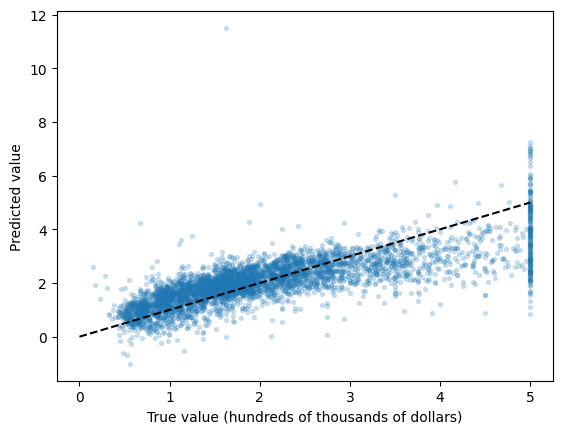

In [ ]:
plt.scatter(y_test, y_test_predicted, alpha=0.2, s=8)
plt.plot([0, 5], [0, 5], "k--")
plt.xlabel("True value (hundreds of thousands of dollars)")
plt.ylabel("Predicted value")
plt.show()

Three things a single number didn't show:

- The vertical column at 5.0 is the cap: districts whose true value is unknown above \$500,000, predicted anywhere from 1 to 7.
- The cloud bends below the diagonal on the right: the more expensive the district, the more the model underestimates it.
- A line has no limits: 15 districts get a negative predicted value and 39 one above the cap, and one gets 11.5, more than twice the highest value in the data.

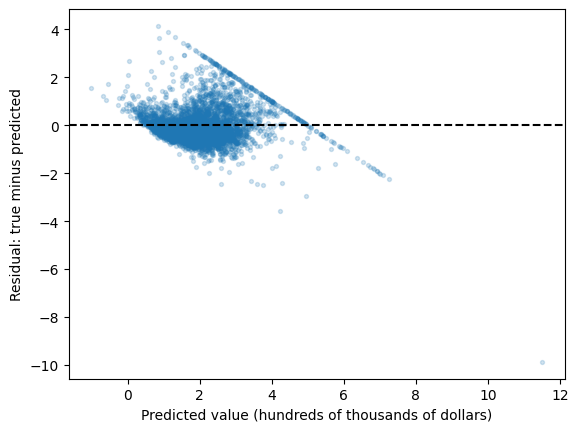

In [ ]:
residuals = y_test - y_test_predicted
plt.scatter(y_test_predicted, residuals, alpha=0.2, s=8)
plt.axhline(0, color="k", linestyle="--")
plt.xlabel("Predicted value (hundreds of thousands of dollars)")
plt.ylabel("Residual: true minus predicted")
plt.show()

The residual is the true value minus the predicted one. For a model whose errors were only noise, the points would form a band of even width around 0. Here they don't. The straight diagonal stripe is the capped districts again: their true value is always 5.0, so their residual falls by exactly one for each unit the prediction rises. Above the band and to the left are expensive districts predicted too low. And alone at the bottom right is the district predicted at 11.5, wrong by about \$1,000,000. Finding out *which* districts these are, and why, is the subject of [Error analysis](../evaluation/error_analysis.ipynb); a more flexible model is the next step: [random forests](../algorithms/tree-based/random_forests.ipynb) and [gradient boosting](../algorithms/tree-based/gradient_boosting.ipynb).